In [1]:
import os
import torch
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
print("CUDA_VISIBLE_DEVICES:", torch.cuda.device_count())
print("Device name:", torch.cuda.get_device_name(0))
print(f"Free: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB / Total: {torch.cuda.mem_get_info()[1]/1e9:.2f} GB")

CUDA_VISIBLE_DEVICES: 1
Device name: NVIDIA A100-PCIE-40GB
Free: 12.66 GB / Total: 42.41 GB


## 1. Загрузка и описание данных

**Датасет:** Amazon Reviews 2023, категория *Video Games* (McAuley Lab, UC San Diego).

**Источник:** https://amazon-reviews-2023.github.io/

**Что рекомендуем.** Для каждого пользователя строим персональный top-10 видеоигр, которые он с наибольшей вероятностью купит и положительно оценит в будущем.

**Что считаем релевантным.** Игра релевантна пользователю, если в тестовом периоде он оставил на неё отзыв с оценкой ≥ 4. Критерий единый для всех моделей, обучающие таргеты у моделей могут отличаться.

### Поля отзывов (взаимодействия)

| Поле | Смысл |
|---|---|
| `user_id` | идентификатор пользователя |
| `parent_asin` | идентификатор объекта (игры), объединяет варианты и издания одного товара |
| `rating` | явная оценка от 1 до 5 |
| `timestamp` | время отзыва (Unix, миллисекунды) |
| `helpful_vote` | число голосов «полезно» за отзыв |
| `verified_purchase` | подтверждена ли покупка |
| `text_len` | длина текста отзыва |

### Поля метаданных (объекты)

| Поле | Смысл |
|---|---|
| `title` | название игры |
| `main_category`, `categories` | категории Amazon |
| `store` | издатель / бренд |
| `price` | цена |
| `average_rating`, `rating_number` | средняя оценка и число оценок на момент выгрузки |
| `features`, `description` | текстовые описания |
| `details` | словарь характеристик (платформа, дата выхода и др.) |

**Что взаимодействие означает.** Запись в данных - это отзыв пользователя на купленную игру с оценкой. Покупка без отзыва в данных не наблюдается, поэтому обратная связь неполная (наблюдаются только оценённые товары).

In [2]:
from pathlib import Path
import subprocess
import pandas as pd
import time

DATA = Path("data/raw"); DATA.mkdir(parents=True, exist_ok=True)
BASE = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw"
URLS = {
    "reviews": f"{BASE}/review_categories/Video_Games.jsonl.gz",
    "meta":    f"{BASE}/meta_categories/meta_Video_Games.jsonl.gz",
}
REV_PQ, META_PQ = DATA / "reviews.parquet", DATA / "meta.parquet"

def download(url, out, retries=30):
    for i in range(retries):
        r = subprocess.run(["curl", "-fL", "-C", "-", "--retry", "5",
                            "--retry-delay", "5", url, "-o", str(out)])
        if r.returncode == 0:
            return
        print(f"retry {i+1}, returncode={r.returncode}")
        time.sleep(5)
    raise RuntimeError(f"Не удалось скачать {url}")

for name, url in URLS.items():
    pq = REV_PQ if name == "reviews" else META_PQ
    gz = DATA / f"{name}.jsonl.gz"
    if not pq.exists():
        download(url, gz)   
        subprocess.run(["gzip", "-t", str(gz)], check=True)

In [3]:
def read_jsonl(path, cols, chunksize=500_000):
    parts = []
    for ch in pd.read_json(path, lines=True, compression="gzip", chunksize=chunksize):
        parts.append(ch[cols])
    return pd.concat(parts, ignore_index=True)

if not REV_PQ.exists():
    rev_cols = ["user_id", "parent_asin", "rating", "timestamp",
                "helpful_vote", "verified_purchase", "text"]
    rev = read_jsonl(DATA / "reviews.jsonl.gz", rev_cols)
    rev["text_len"] = rev["text"].fillna("").str.len().astype("int32")
    rev = rev.drop(columns="text")
    rev.to_parquet(REV_PQ)

if not META_PQ.exists():
    meta_cols = ["parent_asin", "title", "main_category", "categories", "store",
                 "price", "average_rating", "rating_number", "features",
                 "description", "details"]
    meta = read_jsonl(DATA / "meta.jsonl.gz", meta_cols)

    meta["price"] = pd.to_numeric(
        meta["price"].astype(str).str.extract(r"(\d+\.?\d*)")[0], errors="coerce"
    )
    
    import json
    for c in ["categories", "features", "description", "details"]:
        meta[c] = meta[c].apply(lambda x: json.dumps(x, ensure_ascii=False))
    for c in ["title", "main_category", "store"]:
        meta[c] = meta[c].astype("string")

    meta.to_parquet(META_PQ)

rev, meta = pd.read_parquet(REV_PQ), pd.read_parquet(META_PQ)
print(rev.shape, meta.shape)
rev.head()

(4624615, 7) (137269, 11)


,user_id,parent_asin,rating,timestamp,helpful_vote,verified_purchase,text_len
0,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B07DK1H3H5,4,2020-12-17 06:33:24.795,0,True,226
1,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B07SRWRH5D,5,2020-04-16 15:31:54.941,1,False,85
2,AGXVBIUFLFGMVLATYXHJYL4A5Q7Q,B07MFMFW34,5,2017-03-30 12:37:11.000,0,True,78
3,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B0BCHWZX95,5,2019-12-29 16:40:34.017,0,True,196
4,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B00HUWA45W,5,2015-03-29 01:18:52.000,0,True,194


## 2. EDA и подготовка данных

Проверим качество сырых данных, активность пользователей, популярность объектов и метаданные, а затем сформируем итоговую выборку для моделей.

**Что делаем.** Сначала мы анализируем сырые данные: пропуски, дубликаты пар (user, item), период, распределения оценок и активности. Затем очищаем данные: убираем строки без ключевых полей и объекты без метаданных, а для каждой пары (user, item) оставляем первое по времени взаимодействие. После этого применяем итеративный 10-core, то есть оставляем пользователей и объекты минимум с 10 взаимодействиями. Если после фильтрации данных окажется слишком много, предусмотрена случайная подвыборка пользователей с фиксированным seed (`MAX_INTER`). В завершение изучаем итоговую выборку: разреженность, активность, популярность объектов и покрытие метаданных.

**Обоснование.** Поскольку модели и метрики предполагают одну запись на пару (user, item), мы оставили только первое взаимодействие, которое соответствует первой покупке. FM использует признаки объектов, поэтому мы исключили объекты без метаданных. Так как большинство пользователей в сырых данных оставили лишь один отзыв, по такой истории нельзя ни обучить персональную модель, ни выделить validation и test по времени, а редкие объекты не получают надёжных представлений, поэтому мы выбрали 10-core как компромисс между размером выборки и достаточной историей. Подвыборка пользователей целиком сохраняет их истории и воспроизводима за счёт фиксированного seed. Поля `average_rating` и `rating_number` мы не используем в признаках, поскольку они посчитаны по всем отзывам, включая будущие, и привели бы к утечке.

**Ограничение.** После жёсткой фильтрации выборка состоит из активных пользователей и популярных объектов, поэтому выводы не переносятся на холодный старт.

Конфигурация, сырые данные, пропуски, дубликаты

In [4]:
import json, numpy as np, matplotlib.pyplot as plt
import scipy.sparse as sp
SEED = 42
rng = np.random.default_rng(SEED)
K_USER, K_ITEM = 10, 10        # порог k-core
MAX_INTER = 1_500_000          # верхняя граница размера выборки
PROC = Path("data/processed"); PROC.mkdir(parents=True, exist_ok=True)

n_raw = len(rev)
rev["dt"] = pd.to_datetime(rev["timestamp"], unit="ms")
print("Сырых отзывов:", n_raw, "| пользователей:", rev.user_id.nunique(),
      "| объектов:", rev.parent_asin.nunique())

print("\nПропуски в отзывах:\n", rev.isna().sum())
print("\nПропуски в метаданных (доля):\n", meta[["title", "store", "price", "main_category"]].isna().mean().round(3))
print("Пустые categories:", (meta["categories"] == "[]").mean().round(3))
print("Дубликаты (user, item):", rev.duplicated(["user_id", "parent_asin"]).sum())
print("Полные дубликаты строк:", rev.duplicated().sum())
print("Дубликаты parent_asin в meta:", meta.parent_asin.duplicated().sum())
print("Период:", rev.dt.min(), "-", rev.dt.max())

Сырых отзывов: 4624615 | пользователей: 2766656 | объектов: 137249

Пропуски в отзывах:
 user_id              0
parent_asin          0
rating               0
timestamp            0
helpful_vote         0
verified_purchase    0
text_len             0
dt                   0
dtype: int64

Пропуски в метаданных (доля):
 title            0.000
store            0.032
price            0.548
main_category    0.080
dtype: float64
Пустые categories: 0.092
Дубликаты (user, item): 69115
Полные дубликаты строк: 53650
Дубликаты parent_asin в meta: 0
Период: 1998-11-17 19:58:49 - 2023-09-12 09:02:35.529000


EDA сырых данных 

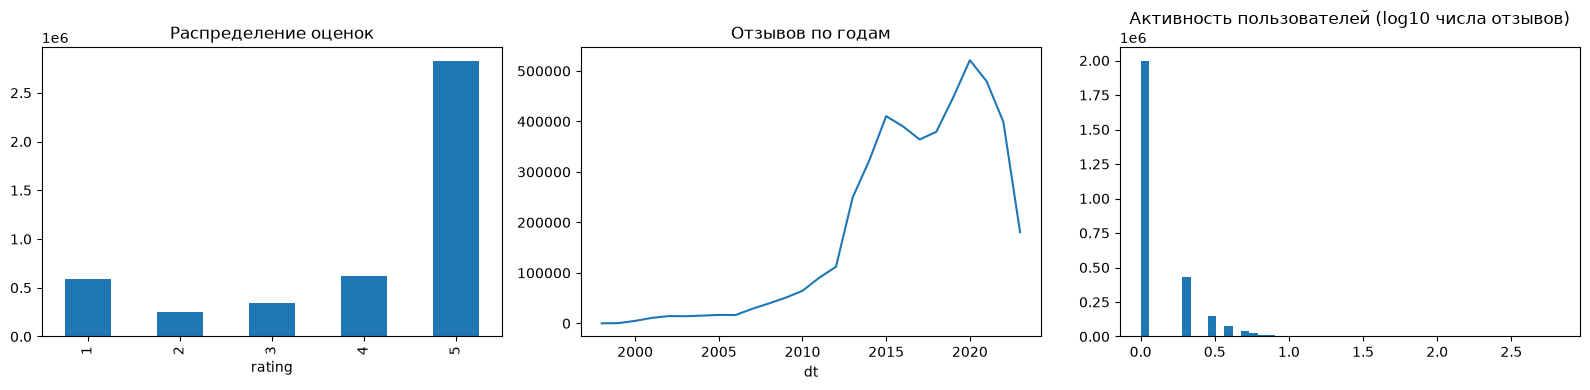

Доля оценок >=4: 0.745
Доля verified: 0.861
Пользователей с 1 отзывом: 0.722


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
rev["rating"].value_counts().sort_index().plot.bar(ax=ax[0], title="Распределение оценок")
rev.groupby(rev.dt.dt.year).size().plot(ax=ax[1], title="Отзывов по годам")
ax[2].hist(np.log10(rev.groupby("user_id").size()), bins=50)
ax[2].set(title="Активность пользователей (log10 числа отзывов)")
plt.tight_layout(); plt.show()

print("Доля оценок >=4:", (rev.rating >= 4).mean().round(3))
print("Доля verified:", rev.verified_purchase.mean().round(3))
uc = rev.groupby("user_id").size()
print("Пользователей с 1 отзывом:", (uc == 1).mean().round(3))

Очистка, k-core, подвыборка

In [6]:
# Очистка
df = rev.dropna(subset=["user_id", "parent_asin", "rating", "timestamp"])
df = df[df.rating.between(1, 5)]
df = df[df.parent_asin.isin(meta.parent_asin)]
df = df.sort_values("timestamp").drop_duplicates(["user_id", "parent_asin"], keep="first")
print("После очистки:", len(df))

# k-core
def kcore(d, k_u, k_i):
    while True:
        n = len(d)
        d = d[d.groupby("user_id")["user_id"].transform("size") >= k_u]
        d = d[d.groupby("parent_asin")["parent_asin"].transform("size") >= k_i]
        if len(d) == n:
            return d

df = kcore(df, K_USER, K_ITEM)
print(f"После {K_USER}-core: {len(df)} взаимодействий, "
      f"{df.user_id.nunique()} пользователей, {df.parent_asin.nunique()} объектов")

# Подвыборка пользователей
if len(df) > MAX_INTER:
    frac = MAX_INTER / len(df)
    users = df.user_id.drop_duplicates()
    keep = users.sample(frac=frac, random_state=SEED)
    df = kcore(df[df.user_id.isin(keep)], K_USER, K_ITEM)
    print("После подвыборки:", len(df))

df = df.reset_index(drop=True)

После очистки: 4555500
После 10-core: 196508 взаимодействий, 11658 пользователей, 5335 объектов


EDA итоговых данных, метаданные, сохранение

Итог: 196508 взаимодействий, 11658 пользователей, 5335 объектов
Разреженность: 99.6840%
Доля оценок >=4 (релевантные): 0.810
Период: 2000-01-03 - 2023-06-28

Взаимодействий на пользователя:
 count    11658.0
mean        16.9
std         12.4
min         10.0
25%         11.0
50%         13.0
75%         18.0
max        327.0
dtype: float64

Взаимодействий на объект:
 count    5335.0
mean       36.8
std        50.0
min        10.0
25%        13.0
50%        20.0
75%        38.0
max       793.0
dtype: float64


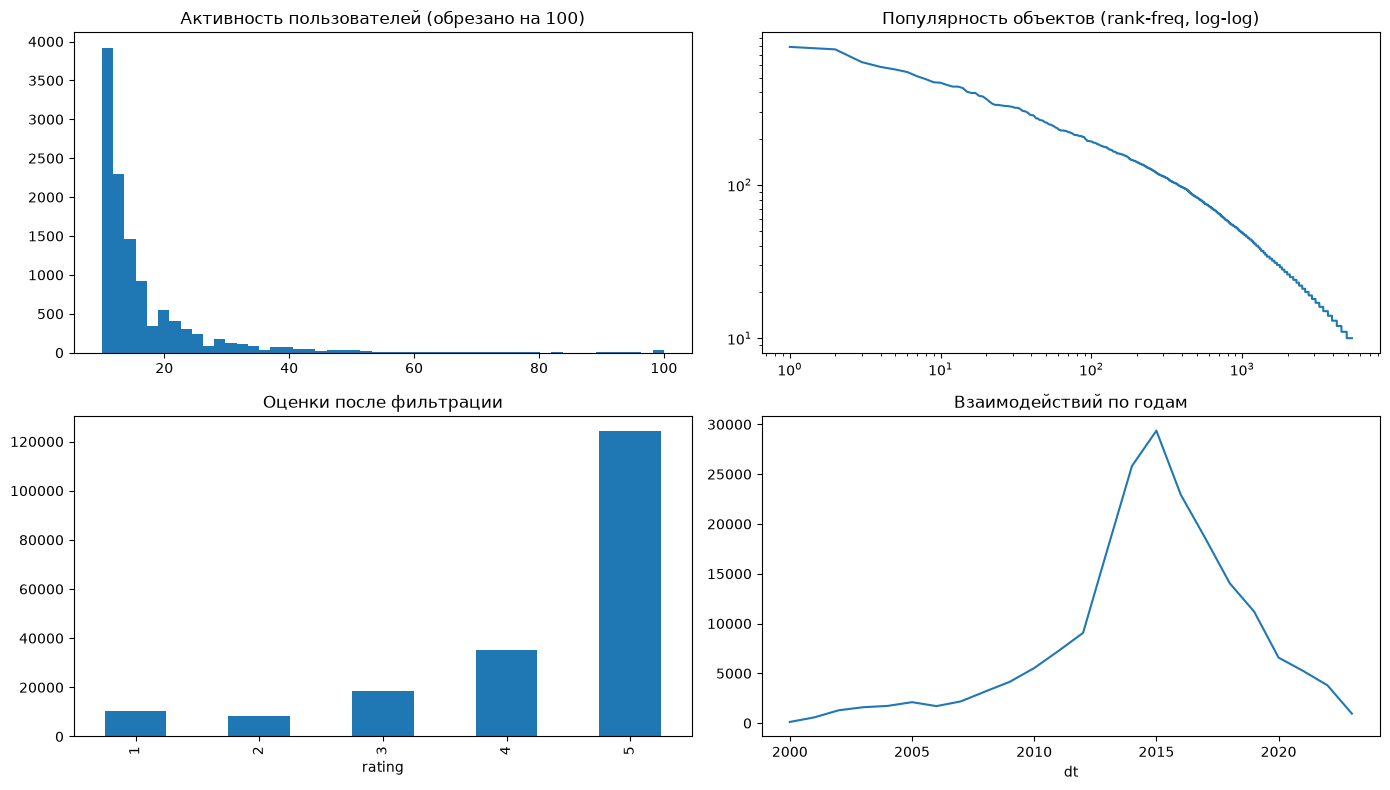

Доля взаимодействий на топ-10 объектов: 2.957%
Доля взаимодействий на топ-10% объектов: 41.013%

Покрытие метаданных:
{'title': np.float64(1.0), 'store': np.float64(0.9985004686035613), 'price': np.float64(0.7955014058106842), 'categories': np.float64(0.981630740393627), 'description': np.float64(0.9162136832239925)}
Топ-10 store:
 store
Nintendo                      693
Electronic Arts               355
PlayStation                   309
Microsoft                     219
ACTIVISION                    204
Ubisoft                       201
Square Enix                   191
Capcom                        162
SEGA                          148
BANDAI NAMCO Entertainment    143
Name: count, dtype: int64[pyarrow]
Уникальных store: 506


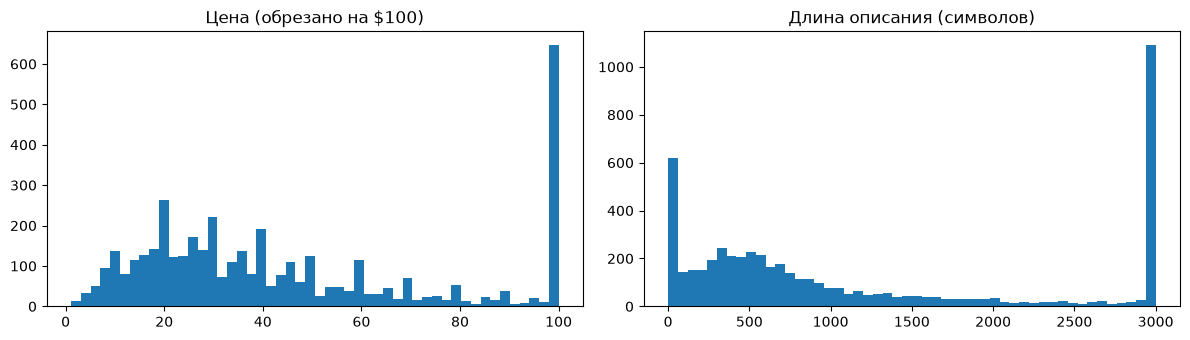

In [7]:
n_u, n_i = df.user_id.nunique(), df.parent_asin.nunique()
print(f"Итог: {len(df)} взаимодействий, {n_u} пользователей, {n_i} объектов")
print(f"Разреженность: {1 - len(df)/(n_u*n_i):.4%}")
print(f"Доля оценок >=4 (релевантные): {(df.rating >= 4).mean():.3f}")
print("Период:", df.dt.min().date(), "-", df.dt.max().date())

uc, ic = df.groupby("user_id").size(), df.groupby("parent_asin").size()
print("\nВзаимодействий на пользователя:\n", uc.describe().round(1))
print("\nВзаимодействий на объект:\n", ic.describe().round(1))

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0,0].hist(uc.clip(upper=100), bins=50); ax[0,0].set(title="Активность пользователей (обрезано на 100)")
ax[0,1].loglog(np.arange(1, n_i+1), np.sort(ic.values)[::-1]); ax[0,1].set(title="Популярность объектов (rank-freq, log-log)")
df.rating.value_counts().sort_index().plot.bar(ax=ax[1,0], title="Оценки после фильтрации")
df.groupby(df.dt.dt.year).size().plot(ax=ax[1,1], title="Взаимодействий по годам")
plt.tight_layout(); plt.show()

top10 = ic.sort_values(ascending=False).head(10).cumsum().iloc[-1] / len(df)
print(f"Доля взаимодействий на топ-10 объектов: {top10:.3%}")
print(f"Доля взаимодействий на топ-10% объектов: {ic.sort_values(ascending=False).head(n_i//10).sum()/len(df):.3%}")

# Метаданные для оставшихся объектов
items = meta[meta.parent_asin.isin(df.parent_asin)].drop_duplicates("parent_asin").reset_index(drop=True)
items["cats"] = items["categories"].apply(json.loads)
items["n_cats"] = items["cats"].apply(len)
items["n_features"] = items["features"].apply(lambda x: len(json.loads(x)))
items["desc_len"] = items["description"].apply(lambda x: len(" ".join(json.loads(x))))
print("\nПокрытие метаданных:")
print({"title": items.title.notna().mean(), "store": items.store.notna().mean(),
       "price": items.price.notna().mean(), "categories": (items.n_cats > 0).mean(),
       "description": (items.desc_len > 0).mean()})
print("Топ-10 store:\n", items.store.value_counts().head(10))
print("Уникальных store:", items.store.nunique())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(items.price.dropna().clip(upper=100), bins=50); ax[0].set(title="Цена (обрезано на $100)")
ax[1].hist(items.desc_len.clip(upper=3000), bins=50); ax[1].set(title="Длина описания (символов)")
plt.tight_layout(); plt.show()

df[["user_id","parent_asin","rating","timestamp","helpful_vote","verified_purchase","text_len"]].to_parquet(PROC / "interactions.parquet")
items.drop(columns=["cats"]).to_parquet(PROC / "items.parquet")

## 3. Протокол оценки

Глобальное временное разбиение 80/10/10: train (до 2018-02-22), validation (до 2019-09-17) и test (после). Так модель обучается только на прошлом и проверяется на будущем, как в реальной системе, а случайное разбиение допустило бы утечку из будущего. Гиперпараметры подбираются на validation по истории train; для финального сравнения модели с выбранными настройками переобучаются на train+val и один раз оцениваются на test.

Кандидатами служат все объекты, встречавшиеся в истории (train для validation, train+val для test), поэтому новые объекты в выдачу не попадают и из ground truth исключаются. Оцениваются только пользователи с историей и хотя бы одним релевантным объектом в целевом периоде, холодный старт для новых пользователей вне задачи. Релевантным считается объект с оценкой ≥ 4 в целевом периоде, и этот критерий одинаков для всех моделей независимо от их обучающего таргета. Все объекты из истории пользователя исключаются из выдачи. Основная метрика выбрана до подбора: NDCG@10, так как она учитывает позицию релевантных объектов в top-10. Дополнительно считаем Recall@10 (полнота) и Coverage@10 (разнообразие выдачи). Для проверки протокола запущен бейзлайн по популярности (NDCG@10 = 0.0105 на validation).

In [8]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
K, REL_T = 10, 4 # top-K и порог релевантности 

df = pd.read_parquet(PROC / "interactions.parquet").sort_values("timestamp").reset_index(drop=True)
if np.issubdtype(df.timestamp.dtype, np.datetime64):
    df["timestamp"] = df["timestamp"].astype("datetime64[ms]").astype("int64")
items = pd.read_parquet(PROC / "items.parquet")

uid = {u: i for i, u in enumerate(df.user_id.unique())}
iid = {a: i for i, a in enumerate(items.parent_asin)}
df["u"], df["i"] = df.user_id.map(uid), df.parent_asin.map(iid)
n_users, n_items = len(uid), len(iid)

# разбиение 80/10/10
t_val, t_test = df.timestamp.quantile([0.8, 0.9])
df["split"] = np.where(df.timestamp <= t_val, "train",
               np.where(df.timestamp <= t_test, "val", "test"))
train, val, test = (df[df.split == s] for s in ["train", "val", "test"])
print(df.split.value_counts())
print("Границы:", pd.to_datetime(t_val, unit="ms").date(), pd.to_datetime(t_test, unit="ms").date())

split
train    157206
val       19651
test      19651
Name: count, dtype: int64
Границы: 2018-02-22 2019-09-17


In [9]:
def to_csr(d, vals=None):
    v = np.ones(len(d), np.float32) if vals is None else vals
    return sp.csr_matrix((v, (d.u.values, d.i.values)), shape=(n_users, n_items))

def build_eval(history, target):
    """history: известные взаимодействия (исключаются из выдачи); target: период оценки."""
    known_items = np.zeros(n_items, bool); known_items[history.i.unique()] = True   # кандидаты
    known_users = history.u.unique()
    t = target[(target.rating >= REL_T) & known_items[target.i.values] & target.u.isin(known_users)]
    return dict(users=np.sort(t.u.unique()), seen=to_csr(history).tocsr(),
                truth=to_csr(t).tocsr(), cand=torch.tensor(known_items, device=DEVICE))

ev_val  = build_eval(train, val)                                  
ev_test = build_eval(pd.concat([train, val]), test)               
for n, e in [("val", ev_val), ("test", ev_test)]:
    print(n, "пользователей:", len(e["users"]), "| кандидатов:", int(e["cand"].sum()),
          "| релевантных пар:", e["truth"].nnz)

@torch.no_grad()
def evaluate(score_fn, ev, k=K, bs=2048):
    """score_fn(user_ids: LongTensor) -> Tensor [len(users), n_items]. Возвращает метрики @k."""
    ndcg, rec, rec_items = [], [], set()
    disc = 1.0 / torch.log2(torch.arange(2, k + 2, device=DEVICE).float())
    for s in range(0, len(ev["users"]), bs):
        ub = ev["users"][s:s + bs]
        sc = score_fn(torch.as_tensor(ub, device=DEVICE)).float()
        seen = torch.tensor(ev["seen"][ub].toarray() > 0, device=DEVICE)
        sc = sc.masked_fill(seen | ~ev["cand"], -float("inf"))
        top = sc.topk(k, dim=1).indices
        truth = torch.tensor(ev["truth"][ub].toarray() > 0, device=DEVICE)
        hits = truth.gather(1, top).float()
        n_rel = truth.sum(1).float()
        idcg = torch.cumsum(disc, 0)[(n_rel.clamp(max=k) - 1).long()]
        ndcg.append(((hits * disc).sum(1) / idcg).cpu()); rec.append((hits.sum(1) / n_rel).cpu())
        rec_items |= set(top.flatten().tolist())
    return {f"NDCG@{k}": torch.cat(ndcg).mean().item(), f"Recall@{k}": torch.cat(rec).mean().item(),
            f"Coverage@{k}": len(rec_items) / int(ev["cand"].sum())}

pop = torch.tensor(np.bincount(train.i, minlength=n_items), device=DEVICE).float()
print("Popularity (val):", evaluate(lambda u: pop.expand(len(u), -1), ev_val))

val пользователей: 2753 | кандидатов: 4629 | релевантных пар: 8305
test пользователей: 2472 | кандидатов: 4988 | релевантных пар: 6763
Popularity (val): {'NDCG@10': 0.010544179007411003, 'Recall@10': 0.013108029030263424, 'Coverage@10': 0.004104558219917909}


## 4. Запуск моделей

Импорты, обёртка моделей, пробный запуск

In [10]:
%load_ext autoreload
%autoreload 2
import time, json, optuna
import pickle
from models.knn import ItemKNN
from models.ials import IALS
from models.ease import EASE
from models.fm import FM, build_item_meta
from models.ials_custom import IALSCustom
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [13]:
Xm, n_attr = build_item_meta(items, seed=SEED)
pos_csr = lambda h: to_csr(h[h.rating >= REL_T])  # rating >= 4

# fit(params, history) -> обученная модель; history = train (подбор) или train+val (финал)
FIT = {
    "ItemKNN":     lambda p, h: ItemKNN(**p, device=DEVICE).fit(pos_csr(h)),
    "iALS":        lambda p, h: IALS(**p, bs=256, seed=SEED, device=DEVICE).fit(pos_csr(h)),
    "EASE":        lambda p, h: EASE(**p, device=DEVICE).fit(pos_csr(h)),
    "FM":          lambda p, h: FM(**p, seed=SEED, device=DEVICE).fit(h, Xm, n_attr, n_users, n_items),
    "iALS-custom": lambda p, h: IALSCustom(**p, bs=256, seed=SEED, device=DEVICE).fit(h, n_users, n_items),
}

# Пространства поиска
SPACE = {
    "ItemKNN": lambda t: dict(k=t.suggest_int("k", 10, 500, log=True),
                              shrink=t.suggest_float("shrink", 0, 100),
                              alpha=t.suggest_float("alpha", 0, 1)),
    "iALS": lambda t: dict(factors=t.suggest_categorical("factors", [32, 64, 128]),
                           reg=t.suggest_float("reg", 1e-3, 10, log=True),
                           alpha=t.suggest_float("alpha", 1, 100, log=True),
                           iters=t.suggest_int("iters", 5, 20)),
    "EASE": lambda t: dict(lam=t.suggest_float("lam", 1, 1e4, log=True)),
    "FM": lambda t: dict(d=t.suggest_categorical("d", [16, 32, 64]),
                         lr=t.suggest_float("lr", 1e-4, 1e-2, log=True),
                         reg=t.suggest_float("reg", 1e-7, 1e-3, log=True),
                         epochs=t.suggest_int("epochs", 10, 40),
                         n_neg=t.suggest_categorical("n_neg", [1, 4, 8])),
    "iALS-custom": lambda t: dict(factors=t.suggest_categorical("factors", [32, 64, 128]),
                                  reg=t.suggest_float("reg", 1e-3, 10, log=True),
                                  alpha=t.suggest_float("alpha", 1, 100, log=True),
                                  iters=t.suggest_int("iters", 5, 20),
                                  tau=t.suggest_float("tau", 3.0, 4.5),
                                  gamma=t.suggest_float("gamma", 0.5, 4.0),
                                  half_life=t.suggest_float("half_life", 180, 3650, log=True),
                                  w_min=t.suggest_float("w_min", 0.05, 0.5)),
}
N_TRIALS = {"ItemKNN": 25, "iALS": 25, "EASE": 20, "FM": 20, "iALS-custom": 25}

# проверка
defaults = {"ItemKNN": dict(k=50, shrink=10, alpha=0.5), "iALS": dict(factors=64, reg=0.1, alpha=20, iters=10),
            "EASE": dict(lam=500), "FM": dict(d=32, lr=1e-3, reg=1e-5, epochs=10),
            "iALS-custom": dict(factors=64, reg=0.1, alpha=20, iters=10)}
for name, p in defaults.items():
    t0 = time.time(); m = FIT[name](p, train)
    print(f"{name:12s} {time.time()-t0:6.1f}s", {k: round(v, 4) for k, v in evaluate(m.score, ev_val).items()})
    del m; torch.cuda.empty_cache()

ItemKNN         0.4s {'NDCG@10': 0.024, 'Recall@10': 0.0351, 'Coverage@10': 0.7265}
iALS            3.4s {'NDCG@10': 0.0278, 'Recall@10': 0.04, 'Coverage@10': 0.2895}
EASE            0.9s {'NDCG@10': 0.0272, 'Recall@10': 0.0413, 'Coverage@10': 0.3692}
FM              9.0s {'NDCG@10': 0.0268, 'Recall@10': 0.0387, 'Coverage@10': 0.04}
iALS-custom     4.7s {'NDCG@10': 0.0303, 'Recall@10': 0.0445, 'Coverage@10': 0.2162}


Подбор гиперпараметров. Основная метрика - NDCG@10.

In [15]:
studies = {}
for name in FIT:
    def objective(trial, name=name):
        m = FIT[name](SPACE[name](trial), train)          
        res = evaluate(m.score, ev_val)
        for k, v in res.items(): trial.set_user_attr(k, v)
        del m; torch.cuda.empty_cache()
        return res["NDCG@10"]
    t0 = time.time()
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    st.optimize(objective, n_trials=N_TRIALS[name])
    studies[name] = st
    print(f"{name:12s} best val NDCG@10 = {st.best_value:.4f} | {time.time()-t0:.0f}s | {st.best_params}")

BEST = {n: s.best_params for n, s in studies.items()}
json.dump(BEST, open(PROC / "best_params.json", "w"), indent=2)
pd.DataFrame({n: {"val NDCG@10": s.best_value, "val Recall@10": s.best_trial.user_attrs["Recall@10"],
                  "val Coverage@10": s.best_trial.user_attrs["Coverage@10"]} for n, s in studies.items()}).T.round(4)

ItemKNN      best val NDCG@10 = 0.0271 | 15s | {'k': 183, 'shrink': 5.935386929466796, 'alpha': 0.1647055689849097}
iALS         best val NDCG@10 = 0.0287 | 216s | {'factors': 64, 'reg': 1.5877875633041425, 'alpha': 12.07776749527829, 'iters': 12}
EASE         best val NDCG@10 = 0.0283 | 19s | {'lam': 117.78750564614418}
FM           best val NDCG@10 = 0.0466 | 310s | {'d': 16, 'lr': 0.008840771893826586, 'reg': 2.5230889053697358e-05, 'epochs': 15, 'n_neg': 4}
iALS-custom  best val NDCG@10 = 0.0389 | 160s | {'factors': 32, 'reg': 0.560864824578919, 'alpha': 18.474353914688397, 'iters': 12, 'tau': 3.0247141718901718, 'gamma': 0.8058600697756393, 'half_life': 255.76840186476716, 'w_min': 0.08509509553497939}


,val NDCG@10,val Recall@10,val Coverage@10
ItemKNN,0.0271,0.0379,0.5653
iALS,0.0287,0.0434,0.2493
EASE,0.0283,0.0434,0.4219
FM,0.0466,0.0653,0.1313
iALS-custom,0.0389,0.0585,0.1082


In [17]:
trials = pd.concat([s.trials_dataframe().assign(model=n) for n, s in studies.items()])
trials.to_csv(PROC / "trials.csv", index=False)
pickle.dump(studies, open(PROC / "studies.pkl", "wb"))
val_table = pd.DataFrame({n: {"val NDCG@10": s.best_value, **{k: s.best_trial.user_attrs[k] for k in ["Recall@10", "Coverage@10"]}}
                          for n, s in studies.items()}).T.round(4)
val_table.to_csv(PROC / "val_table.csv"); val_table

,val NDCG@10,Recall@10,Coverage@10
ItemKNN,0.0271,0.0379,0.5653
iALS,0.0287,0.0434,0.2493
EASE,0.0283,0.0434,0.4219
FM,0.0466,0.0653,0.1313
iALS-custom,0.0389,0.0585,0.1082


(при повторном запуске)

In [14]:
BEST = json.load(open(PROC / "best_params.json"))
val_table = pd.read_csv(PROC / "val_table.csv", index_col=0)   
trials = pd.read_csv(PROC / "trials.csv")                      
val_table

,val NDCG@10,Recall@10,Coverage@10
ItemKNN,0.0271,0.0379,0.5653
iALS,0.0287,0.0434,0.2493
EASE,0.0283,0.0434,0.4219
FM,0.0466,0.0653,0.1313
iALS-custom,0.0389,0.0585,0.1082


### Модель 1: item-based kNN

Для пользователя $u$ с историей положительных объектов $H_u$ (оценка $\ge 4$) оценка объекта $i$ равна сумме его сходств с объектами из истории, где учитываются только $k$ ближайших соседей $N_k(i)$ объекта $i$:

$$\text{score}(u,i) = \sum_{j \in N_k(i)\cap H_u} s_{ij}, \qquad s_{ij} = \frac{c_{ij}}{n_i^{\alpha}\, n_j^{1-\alpha} + \lambda},$$

где $c_{ij}$ — число общих пользователей, $n_i$ — число пользователей объекта, $\lambda$ — shrinkage, снижающий вес сходств по малому числу общих пользователей (при $\alpha = 0.5$ получается cosine).

### Модель 2: iALS

Предпочтение бинарное: $p_{ui} = 1$, если оценка $\ge 4$, иначе $0$; уверенность $c_{ui} = 1 + \alpha\, p_{ui}$. Минимизируется

$$\mathcal{L} = \sum_{u,i} c_{ui}\,\big(p_{ui} - x_u^\top y_i\big)^2 + \lambda\big(\lVert X\rVert^2 + \lVert Y\rVert^2\big),$$

а факторы обновляются попеременно в замкнутой форме: $x_u = (Y^\top Y + Y^\top (C_u - I) Y + \lambda I)^{-1} Y^\top C_u p_u$ и симметрично для $y_i$. Рекомендация: $\text{score}(u,i) = x_u^\top y_i$.

### Модель 3: EASE

Линейная модель item-item $\hat X = XB$ по бинарной матрице положительных взаимодействий $X$ с запретом самопредсказания:

$$\min_B \lVert X - XB\rVert_F^2 + \lambda \lVert B\rVert_F^2 \quad \text{при} \quad \operatorname{diag}(B)=0.$$

Замкнутое решение: $P = (X^\top X + \lambda I)^{-1}$, $B_{ij} = -P_{ij}/P_{jj}$ при $i \ne j$, $B_{ii}=0$. 

Рекомендация: $\text{score}(u,i) = x_u \cdot B_{\cdot i}$.

### Модель 4: факторизационная машина (FM) с метапризнаками

FM оценивает пару (пользователь, объект) по вектору признаков $x$:

$$\hat y(x) = w_0 + \sum_f w_f x_f + \sum_{f<g} \langle v_f, v_g\rangle x_f x_g,$$

где каждому признаку $f$ соответствует вектор $v_f$ размерности $d$, а парные взаимодействия признаков моделируются скалярными произведениями. Признаки объекта: ID, издатель (топ-100 и «other»), категории (топ-100), ценовой бин (8 квантилей и индикатор «неизвестно»), SVD(32) от TF-IDF названия, features и description. Признаки пользователя: нормированный профиль метапризнаков ранее купленных объектов, $\log$ числа покупок, средняя выставленная оценка и $\log$ числа дней с последней покупки. Признаки выбраны так, чтобы дать FM сигнал, которого нет в ID. Издатель, категории и цена описывают объект и позволяют обобщать на редкие игры с малой историей, а SVD от TF-IDF текста добавляет семантическое сходство игр (серии, жанры), даже если категории размечены грубо. Профиль пользователя по метапризнакам ранее купленных объектов отражает его вкусы (предпочитаемые издатели, жанры, ценовой сегмент), число покупок и средняя оценка отличают активных пользователей от случайных, а время с последней покупки учитывает динамику интереса. Поскольку рекомендация должна использовать только информацию, доступную в момент рекомендации, для каждого обучающего примера признаки пользователя считаются строго по более ранним взаимодействиям, а `average_rating` и `rating_number` не используются из-за утечки из будущего. Цена и описания взяты из текущей выгрузки каталога, и это ограничение.

Для ранжирования используется парное обучение BPR с $n_{neg}$ случайными негативами на положительный пример (оценка $\ge 4$):

$$\mathcal{L} = -\log \sigma\big(\hat y(u, i^+) - \hat y(u, i^-)\big).$$

При фиксированном пользователе слагаемые, зависящие только от него, не меняют порядок объектов, поэтому

$$\text{score}(u, i) = b_i + s_u \cdot s_i, \qquad s = \sum_f x_f v_f, \qquad b_i = \sum_f w_f x_f + \tfrac12\Big(\lVert s_i\rVert^2 - \sum_f x_f^2 \lVert v_f\rVert^2\Big).$$

Это точная формула FM, она считается одним матричным произведением.

### Модель 5: iALS с кастомным целевым сигналом

Базовый iALS видит только факт «оценка $\ge 4$», а остальные оценки считает неизвестными. Поскольку в данных есть полная шкала 1-5, а оценки сильно смещены к высоким (81% $\ge 4$), я заменила бинарный таргет градуированным сигналом с явными негативами. Сначала оцениваем сглаженное смещение пользователя

$$b_u = \frac{\sum_i (r_{ui} - \mu - b_i)}{n_u + \lambda_b}:$$

«четвёрка» от щедрого пользователя говорит меньше, чем от строгого. Смещение объекта не вычитаем, поскольку оно несёт полезный сигнал о качестве игры. Далее:

- целевая степень предпочтения, где $\tau \approx 3.5$ согласован с порогом релевантности на test:
$$p_{ui} = \sigma\big(\gamma\,(r_{ui} - b_u - \tau)\big);$$
- уверенность, при которой сильные мнения (5 и 1-2) весят больше нейтральных:
$$c_{ui} = 1 + \alpha \cdot w_t \cdot |2p_{ui} - 1|;$$
- затухание по возрасту, поскольку предпочтения со временем меняются:
$$w_t = \max\big(2^{-\text{age}/h},\, w_{\min}\big);$$
- ненаблюдаемые пары: $p = 0$, $c = 1$.

Минимизируется

$$\mathcal{L} = \sum_{u,i} c_{ui}\,\big(p_{ui} - x_u^\top y_i\big)^2 + \lambda\big(\lVert X\rVert^2 + \lVert Y\rVert^2\big),$$

обновления ALS:

$$x_u = \big(Y^\top Y + Y^\top (C_u - I) Y + \lambda I\big)^{-1} Y^\top C_u p_u$$

и симметрично для объектов. Отличие от базового iALS в том, что $p_u$ не бинарный, а градуированный, а часть наблюдаемых пар становится явными негативами, то есть меняется сам сигнал, а не только веса confidence. Оценка проходит тем же протоколом: релевантность на test остаётся $\text{rating} \ge 4$.

## 5. Сравнение моделей

Сравнение проводится при $K = 10$ на трёх метриках, выбранных до подбора гиперпараметров. 

**NDCG@10** (основная) оценивает качество ранжирования: пользователь видит короткий список из 10 игр, и релевантная игра на первой позиции полезнее, чем на десятой, а NDCG это учитывает логарифмической скидкой по позиции и нормируется на идеальный порядок, поэтому метрика сопоставима между пользователями с разным числом релевантных объектов. 

**Recall@10** показывает, какую долю игр, которые пользователь позже купил и высоко оценил, удалось поместить в список; он отвечает на прямой вопрос задачи «нашли ли мы то, что ему понравится» и не зависит от порядка внутри top-10. 

**Coverage@10** — доля каталога, попавшая хотя бы в одну рекомендацию; она контролирует разнообразие и популярностное смещение: модель может иметь высокий NDCG, рекомендуя всем одни и те же игры, но для сервиса важно и то, чтобы работали длинный хвост каталога. Coverage не участвует в выборе моделей, а лишь дополняет картину. 

Релевантным на test считается объект с оценкой $\ge 4$ в тестовом периоде, критерий одинаков для всех моделей. Модели переобучены на train+val с гиперпараметрами, выбранными на validation, и оценены на test один раз.

In [15]:
trainval = pd.concat([train, val])

rows = []
for name in FIT:
    t0 = time.time()
    m = FIT[name](BEST[name], trainval)  # переобучение на train+val
    res = evaluate(m.score, ev_test)     # test: настройки зафиксированы
    rows.append({"model": name, **res, "fit_s": round(time.time() - t0, 1)})
    del m; torch.cuda.empty_cache()

# бейзлайн: популярность по train+val
pop = torch.tensor(np.bincount(trainval[trainval.rating >= REL_T].i, minlength=n_items), device=DEVICE).float()
rows.append({"model": "Popularity", **evaluate(lambda u: pop.expand(len(u), -1), ev_test), "fit_s": 0})

test_table = pd.DataFrame(rows).set_index("model").sort_values("NDCG@10", ascending=False)
test_table.round(4).to_csv(PROC / "test_table.csv")
test_table.round(4)

,NDCG@10,Recall@10,Coverage@10,fit_s
model,,,,
iALS-custom,0.0271,0.0373,0.1022,1.7
FM,0.0267,0.0391,0.1269,15.2
EASE,0.0206,0.0303,0.3831,1.4
ItemKNN,0.0199,0.0293,0.5223,1.0
iALS,0.0190,0.0280,0.2344,7.3
Popularity,0.0154,0.0277,0.0040,0.0


In [16]:
pd.DataFrame({n: {k: (round(v, 4) if isinstance(v, float) else v) for k, v in p.items()}
              for n, p in BEST.items()}).T.fillna("")

/tmp/ipykernel_3873725/1119203368.py:2: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  for n, p in BEST.items()}).T.fillna("")


,k,shrink,alpha,factors,reg,iters,lam,d,lr,epochs,n_neg,tau,gamma,half_life,w_min
ItemKNN,183.0,5.9354,0.1647,,,,,,,,,,,,
iALS,,,12.0778,64.0,1.5878,12.0,,,,,,,,,
EASE,,,,,,,117.7875,,,,,,,,
FM,,,,,0.0,,,16.0,0.0088,15.0,4.0,,,,
iALS-custom,,,18.4744,32.0,0.5609,12.0,,,,,,3.0247,0.8059,255.7684,0.0851


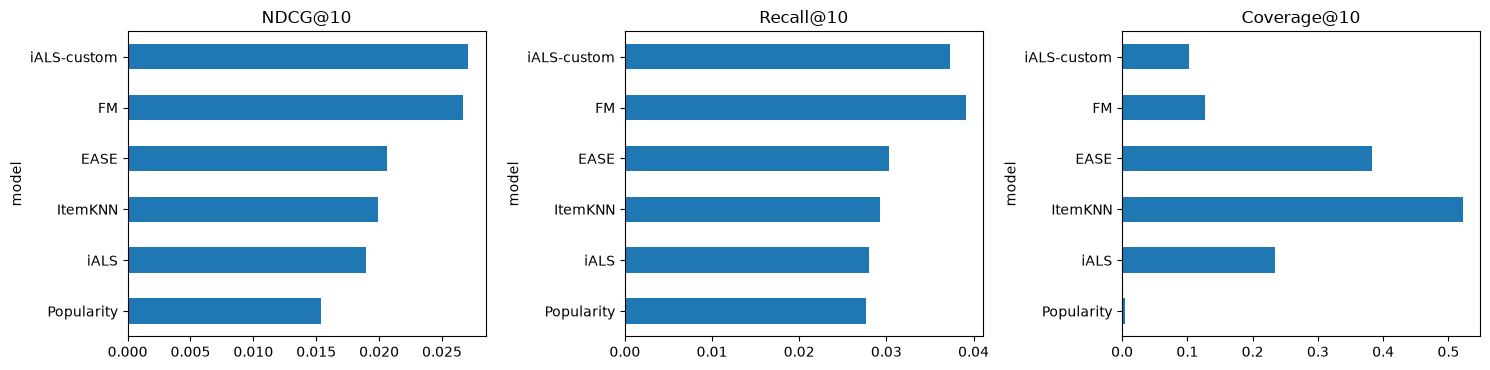

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, met in zip(ax, ["NDCG@10", "Recall@10", "Coverage@10"]):
    test_table[met].plot.barh(ax=a, title=met); a.invert_yaxis()
plt.tight_layout(); plt.show()

Сделаем еще абляцию кастомного сигнала

In [18]:
bp = BEST["iALS-custom"]
variants = {
    "iALS-custom (полная)":        bp,
    "без поправки на смещение":    {**bp, "debias": False},
    "без затухания по времени":    {**bp, "half_life": None},
    "без явных негативов":         {**bp, "tau": 0.0},     # p≈1 для всех наблюдаемых оценок
    "базовый iALS (бинарный)":     None,
}
rows = []
for n, p in variants.items():
    m = FIT["iALS"](BEST["iALS"], train) if p is None else FIT["iALS-custom"](p, train)
    rows.append({"variant": n, **evaluate(m.score, ev_val)})
    del m; torch.cuda.empty_cache()
pd.DataFrame(rows).set_index("variant").round(4)

,NDCG@10,Recall@10,Coverage@10
variant,,,
iALS-custom (полная),0.0389,0.0585,0.1082
без поправки на смещение,0.0389,0.0583,0.1106
без затухания по времени,0.0263,0.0409,0.1666
без явных негативов,0.0405,0.0619,0.1288
базовый iALS (бинарный),0.0287,0.0434,0.2493


## 6. Выводы

**Лучшие методы.** По основной метрике на test впереди iALS-custom (NDCG@10 = 0.0271) и FM (0.0267). Разница между ними 0.0004, при одном разбиении и одном seed её нельзя считать значимой. По Recall@10 FM немного лучше (0.0391 против 0.0373). Все модели обошли бейзлайн по популярности (0.0154) по NDCG, но по Recall базовый iALS (0.0280) почти не отличается от него (0.0277). EASE (0.0206) и ItemKNN (0.0199) оказались лучше базового iALS (0.0190), хотя на validation порядок был другим: у iALS NDCG 0.0287, у EASE 0.0283, у ItemKNN 0.0271.

**Кастомный сигнал.** iALS-custom превосходит базовый iALS на validation (0.0389 против 0.0287) и на test (0.0271 против 0.0190). Абляция на validation показывает, откуда выигрыш:
- Затухание по времени даёт основной вклад: без него NDCG падает до 0.0263, то есть ниже базового iALS (0.0287).
- Поправка на смещение пользователя эффекта не даёт (0.0389 с ней и без неё).
- Явные негативы не помогают: при `tau=0` NDCG выше (0.0405). Это сравнимо с шумом, но пользы от негативов мы не увидели.

Таким образом, выигрыш даёт в основном учёт времени (confidence с затуханием), а не градуированный сигнал с негативами. Это согласуется с временным разбиением: недавние взаимодействия точнее предсказывают ближайшее будущее.

**Метаданные.** FM с метапризнаками и временными признаками пользователя показала лучший результат на validation (0.0466) и один из лучших на test. Эффект метаданных отдельно мы не измеряли (абляции без них нет), поэтому нельзя отделить его от вклада BPR-обучения и временных признаков.

**Разнообразие.** Лучшие по NDCG модели рекомендуют узкий круг объектов (Coverage 0.10 у iALS-custom и 0.13 у FM), а ItemKNN (0.52) и EASE (0.38) охватывают намного больше каталога. Здесь есть компромисс между точностью и разнообразием.

**Ограничения.**
- Одно временное разбиение и один seed, доверительные интервалы не считались, поэтому близкие результаты неразличимы.
- Качество на test заметно ниже, чем на validation (у FM NDCG 0.0466 против 0.0267). Причины: сдвиг во времени, и модели переобучались на train+val с параметрами, подобранными на train.
- Абляция проведена на validation с параметрами, подобранными для полной модели, поэтому она может быть смещена в её пользу.
- Выборка после 10-core состоит из активных пользователей и популярных объектов, холодный старт не оценивался. Цена и описания взяты из текущей выгрузки каталога, а не на момент покупки.